/var/folders/ph/gfnzgrf17f55k76wdlf728rc0000gn/T/ipykernel_54061/682696528.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


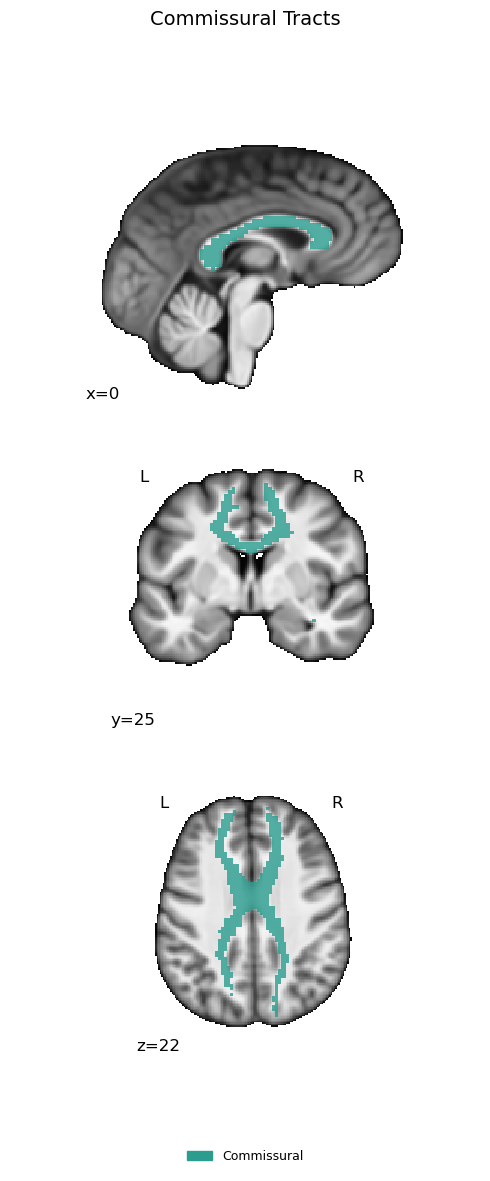

In [2]:
from nilearn import plotting, image
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from scipy.ndimage import gaussian_filter
import os

# ============================================================
# USER SETTINGS — edit these
# ============================================================
TRACT_TYPE = 'Commissural'  # 'Association', 'Commissural', or 'Projection'

SLICE_COORDS = {
    'Association': dict(x=-40, y=10,  z=-17),
    'Commissural': dict(x=0,   y=25,  z=22),
    'Projection':  dict(x=22,  y=13,  z=20),
}
# ============================================================

# ---- Paths - EDIT THESE ----
RESULTS_DIR   = "/path/to/results"
TEMPLATE_DIR  = "/path/to/t1s/control_t1s"   # control template folder (t1_brainextract_template.sh output)
PLOT_DIR      = os.path.join(RESULTS_DIR, "06_figures")

# NOTE: final_regions/ is NOT created by registration_pipe.sh - organize it yourself.
# Copy the template-space tract masks from 04_registration/ROIs_CONspace/ into
# Association/, Commissural/ and Projection/ subfolders (tract groupings as in
# Fig. 1 of Rizor et al., or your own), and create one combined mask per folder:
#   final_regions/Association/All_assoc.nii.gz
#   final_regions/Commissural/All_comm.nii.gz
#   final_regions/Projection/All_proj.nii.gz
MASK_DIR      = os.path.join(RESULTS_DIR, "04_registration", "ROIs_CONspace", "final_regions")

template_path = os.path.join(TEMPLATE_DIR, "control_templatetemplate0.nii.gz")

# Template-space WM mask used to restrict the tract masks to white matter:
# FAST on the control template, WM partial volume thresholded at 0.9 and binarized
wm_mask_path  = os.path.join(TEMPLATE_DIR, "control_temp_WM_mask_2mm.nii.gz")

os.makedirs(PLOT_DIR, exist_ok=True)

TRACT_MASK_PATHS = {
    'Association': f'{MASK_DIR}/Association/All_assoc.nii.gz',
    'Commissural': f'{MASK_DIR}/Commissural/All_comm.nii.gz',
    'Projection':  f'{MASK_DIR}/Projection/All_proj.nii.gz',
}

TRACT_COLORS = {
    'Association': '#E63946',
    'Projection':  '#457B9D',
    'Commissural': '#2A9D8F',
}

# --- resolve selected tract ---
mask_files  = {TRACT_TYPE: TRACT_MASK_PATHS[TRACT_TYPE]}
coords      = SLICE_COORDS[TRACT_TYPE]
custom_cmap = ListedColormap([TRACT_COLORS[TRACT_TYPE]])

views = [
    ('x', 'Sagittal', (coords['x'],)),
    ('y', 'Coronal',  (coords['y'],)),
    ('z', 'Axial',    (coords['z'],)),
]

# --- load WM mask ---
wm_img       = nib.load(wm_mask_path)
ref          = nib.load(list(mask_files.values())[0])

if wm_img.shape != ref.shape:
    from nilearn.image import resample_to_img
    wm_img = resample_to_img(wm_img, ref, interpolation='nearest')

wm_mask_bin = (wm_img.get_fdata() > 0).astype(float)

# --- build combined labeled image ---
combined = np.zeros(ref.shape)

for i, (name, path) in enumerate(mask_files.items(), start=1):
    mask_data    = nib.load(path).get_fdata()
    masked_tract = (mask_data > 0).astype(float) * wm_mask_bin
    smoothed     = gaussian_filter(masked_tract, sigma=0.5)
    combined[smoothed > 0.3] = i

combined_img = nib.Nifti1Image(combined, ref.affine)

# --- smooth template ---
template_img        = nib.load(template_path)
template_smooth     = gaussian_filter(template_img.get_fdata().astype(float), sigma=1)
template_smooth_img = nib.Nifti1Image(template_smooth, template_img.affine)

# --- plot stacked vertically ---
fig, axes = plt.subplots(3, 1, figsize=(5, 12))

for idx, (ax, (display_mode, title, cut)) in enumerate(zip(axes, views)):
    display = plotting.plot_roi(
        combined_img,
        bg_img=template_smooth_img,
        display_mode=display_mode,
        cut_coords=cut,
        axes=ax,
        cmap=custom_cmap,
        vmin=0.5,
        vmax=len(mask_files) + 0.5,
        colorbar=False,
        alpha=0.8,
        black_bg=False,
        draw_cross=False,
        dim=-0.3,
        annotate=True,  # L/R annotation only on top image
    )

legend_handles = [
    mpatches.Patch(color=TRACT_COLORS[TRACT_TYPE], label=TRACT_TYPE)
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=1, fontsize=9,
           frameon=False, bbox_to_anchor=(0.5, 0.01))

plt.suptitle(f'{TRACT_TYPE} Tracts', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, f'tract_rois_{TRACT_TYPE.lower()}.png'), dpi=300, bbox_inches='tight')
plt.show()

/var/folders/ph/gfnzgrf17f55k76wdlf728rc0000gn/T/ipykernel_75509/3942775473.py:67: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  p.show()


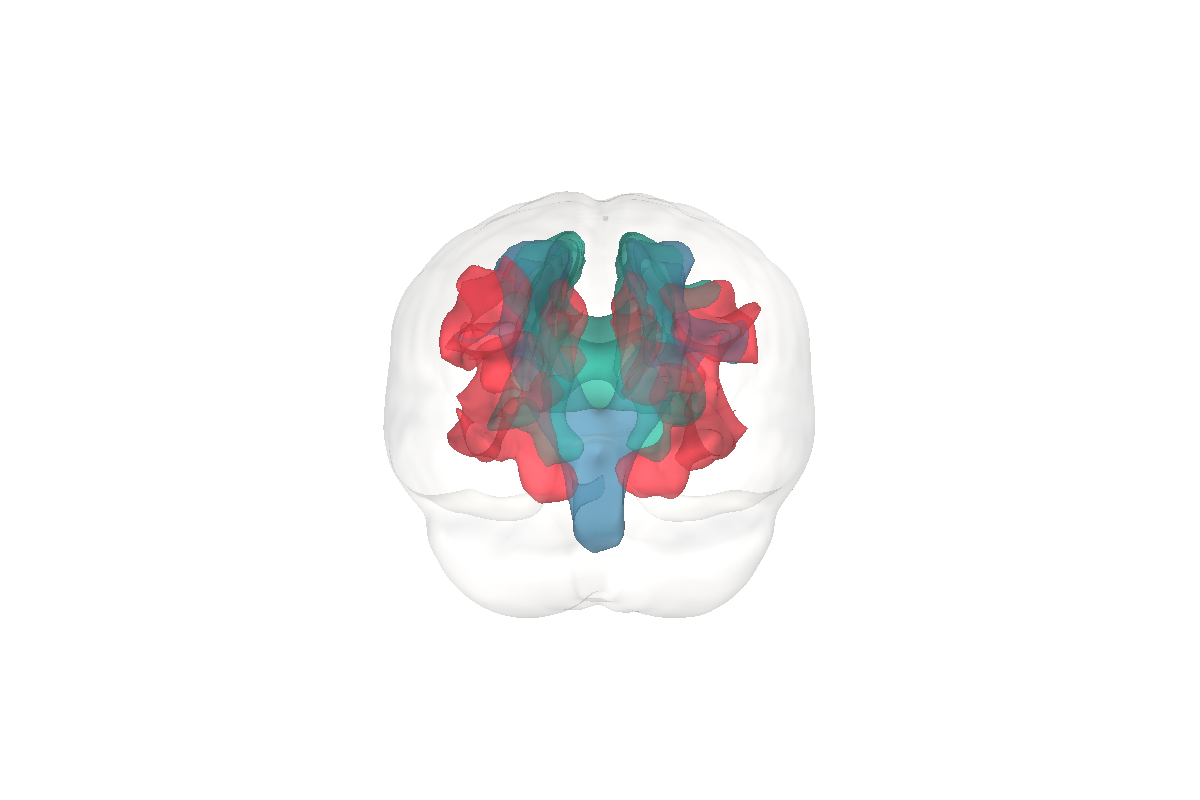

In [2]:
import pyvista as pv
import nibabel as nib
import numpy as np
from skimage import measure

# --- load WM mask once ---
wm_mask_bin = (nib.load(wm_mask_path).get_fdata() > 0).astype(float)

from scipy.ndimage import gaussian_filter

def nii_to_mesh(path, threshold=0.5, wm_mask=None, sigma=1.25):
    img    = nib.load(path)
    data   = img.get_fdata()
    affine = img.affine

    if wm_mask is not None:
        data = (data > 0).astype(float) * wm_mask

    if data.max() < threshold:
        print(f"  Warning: no voxels above threshold in {path}")
        return None

    # smooth volume before meshing — reduces spikiness significantly
    data_smooth = gaussian_filter(data.astype(float), sigma=sigma)

    verts, faces, _, _ = measure.marching_cubes(data_smooth, level=threshold/2)
    verts_mm = nib.affines.apply_affine(affine, verts)
    faces_pv = np.hstack([np.full((len(faces), 1), 3), faces])
    mesh     = pv.PolyData(verts_mm, faces_pv)
    mesh     = mesh.clean()
    mesh     = mesh.smooth_taubin(n_iter=100, pass_band=0.05)

    return mesh

# --- brain mesh (no WM masking on template) ---
brain_mesh = nii_to_mesh(template_path, threshold=0.3)

# --- tract meshes with WM masking ---
assoc_mesh = nii_to_mesh(f'{MASK_DIR}/Association/All_assoc.nii.gz', threshold=0.5, wm_mask=wm_mask_bin)
comm_mesh  = nii_to_mesh(f'{MASK_DIR}/Commissural/All_comm.nii.gz',  threshold=0.5, wm_mask=wm_mask_bin)
proj_mesh  = nii_to_mesh(f'{MASK_DIR}/Projection/All_proj.nii.gz',   threshold=0.5, wm_mask=wm_mask_bin)

# --- plot ---
p = pv.Plotter(off_screen=True, window_size=[1200, 800])

p.add_mesh(brain_mesh, color='white', opacity=0.20,
           smooth_shading=True,
           show_edges=False,     
           edge_color='lightgray',
           line_width=0.1)

p.add_light(pv.Light(position=(1, 1, 1),   focal_point=(0, 0, 0), intensity=0.2))
p.add_light(pv.Light(position=(-1, 0, 0),  focal_point=(0, 0, 0), intensity=0.4))
p.add_light(pv.Light(position=(0, -1, 0),  focal_point=(0, 0, 0), intensity=0.4))

p.add_mesh(assoc_mesh, color='#E63946', opacity=0.9, smooth_shading=True)
p.add_mesh(comm_mesh,  color='#2A9D8F', opacity=0.9, smooth_shading=True)
p.add_mesh(proj_mesh,  color='#457B9D', opacity=0.9, smooth_shading=True)
p.camera_position = 'xz'   # looking down Z axis
p.camera.azimuth  = 0
p.camera.elevation = 0    # 90 = straight down

p.background_color = 'white'
p.screenshot(os.path.join(PLOT_DIR, 'tract_3d.png'), transparent_background=False)
p.show()

  Meshing: UF L (Association) AUC=0.76
  Meshing: UF R (Association) AUC=0.72
  Meshing: IFOF L (Association) AUC=0.75
  Meshing: AF R (Association) AUC=0.73
  Meshing: ILF L (Association) AUC=0.71
  Meshing: CC FMaj (Commissural) AUC=0.72
  Meshing: CC Tap (Commissural) AUC=0.71
  Meshing: CSTr L (Projection) AUC=0.74
  Meshing: CPT L (Projection) AUC=0.73
  Meshing: CPT R (Projection) AUC=0.73
  Meshing: RS L (Projection) AUC=0.73


/var/folders/ph/gfnzgrf17f55k76wdlf728rc0000gn/T/ipykernel_54061/1769233839.py:167: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  p.show()


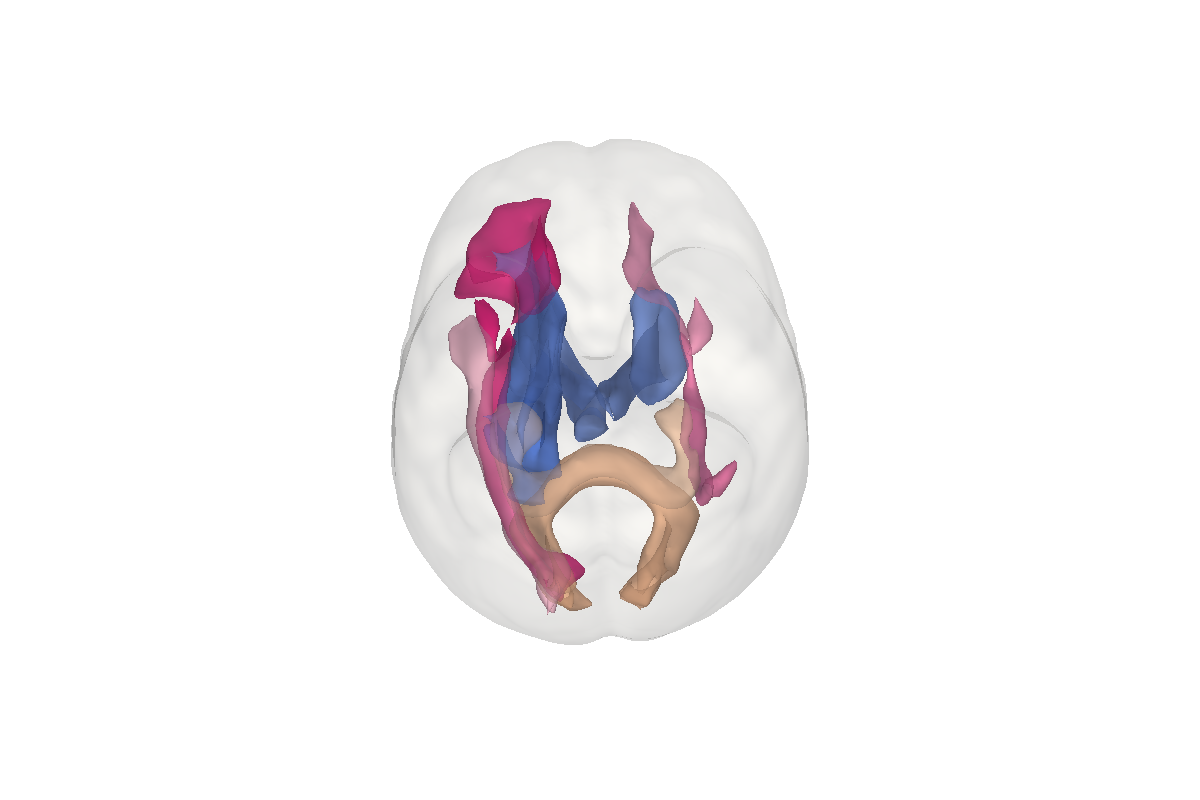

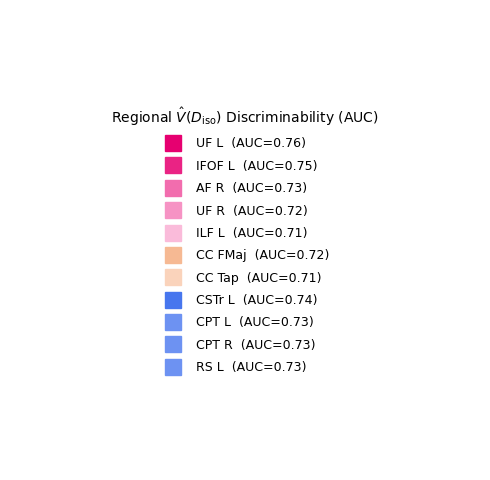

In [3]:
import pyvista as pv
import nibabel as nib
import numpy as np
from skimage import measure
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os

# ============================================================
# USER SETTINGS — list regions and their AUC values
# AUC values are entered by hand from auc_roi.csv, written by stats.ipynb
# (/path/to/results/05_models/auc_roi.csv); copy the 'auc' value for the
# parameter shown (here vison) for each ROI you want to display.
# Region names are the mask file names in final_regions/<tract type>/.
# ============================================================
REGION_FILES = {
    'Association': {
        'MNI_space_thr_50_Uncinate_Fasciculus_L_mask_CONspace':              0.76,
        'MNI_space_thr_50_Uncinate_Fasciculus_R_mask_CONspace':              0.72,
        'MNI_space_thr_50_Inferior_Fronto_Occipital_Fasciculus_L_mask_CONspace': 0.75,
        'MNI_space_thr_50_Arcuate_Fasciculus_R_mask_CONspace':               0.73,
        'MNI_space_thr_50_Inferior_Longitudinal_Fasciculus_L_mask_CONspace': 0.71,
    },
    'Commissural': {
        'MNI_space_thr_50_Corpus_Callosum_Forceps_Major_mask_CONspace': 0.72,
        'MNI_space_thr_50_Corpus_Callosum_Tapetum_mask_CONspace':       0.71,
    },
    'Projection': {
        'MNI_space_thr_50_Corticostriatal_Tract_Superior_L_mask_CONspace':  0.74,
        'MNI_space_thr_50_Corticopontine_Tract_Frontal_L_mask_CONspace':    0.73,
        'MNI_space_thr_50_Corticopontine_Tract_Frontal_R_mask_CONspace':    0.73,
        'MNI_space_thr_50_Reticulospinal_Tract_L_mask_CONspace':            0.73,
    },
}

REGION_LABELS = {
    'MNI_space_thr_50_Uncinate_Fasciculus_L_mask_CONspace':                  'UF L',
    'MNI_space_thr_50_Uncinate_Fasciculus_R_mask_CONspace':                  'UF R',
    'MNI_space_thr_50_Inferior_Fronto_Occipital_Fasciculus_L_mask_CONspace': 'IFOF L',
    'MNI_space_thr_50_Arcuate_Fasciculus_R_mask_CONspace':                   'AF R',
    'MNI_space_thr_50_Inferior_Longitudinal_Fasciculus_L_mask_CONspace':     'ILF L',
    'MNI_space_thr_50_Corpus_Callosum_Forceps_Major_mask_CONspace':          'CC FMaj',
    'MNI_space_thr_50_Corpus_Callosum_Tapetum_mask_CONspace':                'CC Tap',
    'MNI_space_thr_50_Corticostriatal_Tract_Superior_L_mask_CONspace':       'CSTr L',
    'MNI_space_thr_50_Corticopontine_Tract_Frontal_L_mask_CONspace':         'CPT L',
    'MNI_space_thr_50_Corticopontine_Tract_Frontal_R_mask_CONspace':         'CPT R',
    'MNI_space_thr_50_Reticulospinal_Tract_L_mask_CONspace':                 'RS L',
}

TRACT_SUBDIRS = {
    'Association': 'Association',
    'Commissural': 'Commissural',
    'Projection':  'Projection',
}

# base colors per tract type
TRACT_BASE_COLORS = {
    'Association': "#D9006A",  # brighter magenta/pink
    'Commissural': '#F7C09E',  # brighter warm orange
    'Projection':  '#4A76E8',  # brighter indigo-blue
}

# ============================================================

def auc_to_color(auc_val, auc_min, auc_max, hex_color):
    """
    Map AUC value to a shade in HSV space, preserving hue:
    low AUC  -> light, desaturated version of hex_color
    high AUC -> full-saturation, deeper version of hex_color
    """
    rgb = mcolors.to_rgb(hex_color)
    h, s, v = mcolors.rgb_to_hsv(rgb)

    if auc_max == auc_min:
        t = 0.5
    else:
        t = (auc_val - auc_min) / (auc_max - auc_min)

    # light end: high value, lower saturation (washed out but still colored)
    # dark end: full saturation, slightly reduced value (rich, not black)
    s_light, v_light = 0.25, 0.98
    s_dark,  v_dark  = 1.00, 0.90

    s_new = s_light + (s_dark - s_light) * t
    v_new = v_light + (v_dark - v_light) * t

    return mcolors.hsv_to_rgb((h, s_new, v_new))


def nii_to_mesh(path, threshold=0.1, wm_mask=None, sigma=1):
    img    = nib.load(path)
    data   = img.get_fdata()
    affine = img.affine

    if wm_mask is not None:
        data = (data > 0).astype(float) * wm_mask

    if data.max() < threshold:
        print(f"  Warning: no voxels above threshold in {path}")
        return None

    data_smooth              = gaussian_filter(data.astype(float), sigma=sigma)
    verts, faces, _, _       = measure.marching_cubes(data_smooth, level=threshold / 2)
    verts_mm                 = nib.affines.apply_affine(affine, verts)
    faces_pv                 = np.hstack([np.full((len(faces), 1), 3), faces])
    mesh                     = pv.PolyData(verts_mm, faces_pv)
    mesh                     = mesh.clean()
    mesh                     = mesh.smooth_taubin(n_iter=100, pass_band=0.05)
    return mesh


# --- load WM mask ---
wm_mask_bin = (nib.load(wm_mask_path).get_fdata() > 0).astype(float)

# --- brain mesh ---
brain_mesh    = nii_to_mesh(template_path, threshold=0.3)

# --- collect all AUC values globally for normalization ---
all_auc_values = [
    auc
    for tract_dict in REGION_FILES.values()
    for auc in tract_dict.values()
]
global_auc_min = min(all_auc_values)
global_auc_max = max(all_auc_values)

# --- build region meshes colored by AUC ---
region_meshes = []  # (mesh, color, label, tract_type, auc)

for tract_type, region_dict in REGION_FILES.items():
    base_color = TRACT_BASE_COLORS[tract_type]
    subdir     = TRACT_SUBDIRS[tract_type]

    for region_name, auc_val in region_dict.items():
        path  = f'{MASK_DIR}/{subdir}/{region_name}.nii.gz'
        color = auc_to_color(auc_val, global_auc_min, global_auc_max, base_color)

        # use friendly label if provided, else clean the filename
        label = REGION_LABELS.get(
            region_name,
            region_name.replace('MNI_space_thr_50_', '').replace('_mask_CONspace', '')
        )

        print(f"  Meshing: {label} ({tract_type}) AUC={auc_val:.2f}")
        mesh = nii_to_mesh(path, threshold=0.5, wm_mask=wm_mask_bin)
        if mesh is not None:
            region_meshes.append((mesh, color, label, tract_type, auc_val))

# --- plot ---
p = pv.Plotter(off_screen=True, window_size=[1200, 800])

p.add_mesh(brain_mesh, color='white', opacity=0.20,
           smooth_shading=True, show_edges=False,
           edge_color='lightgray', line_width=0.1)

p.add_light(pv.Light(position=(1,  1, 1), focal_point=(0, 0, 0), intensity=0.1))
p.add_light(pv.Light(position=(-1, 0, 0), focal_point=(0, 0, 0), intensity=0.1))
p.add_light(pv.Light(position=(0, -1, 0), focal_point=(0, 0, 0), intensity=0.1))

for mesh, color, label, tract_type, auc_val in region_meshes:
    p.add_mesh(mesh, color=color, opacity=0.9, smooth_shading=True)

p.camera_position = 'xy'
p.camera.azimuth  = 0
p.camera.elevation = 0

p.background_color = 'white'
p.screenshot(os.path.join(PLOT_DIR, 'tract_3d_regions.png'), transparent_background=False)
p.show()

# --- legend sorted by tract type then AUC ---
region_meshes_sorted = sorted(region_meshes, key=lambda x: (x[3], -x[4]))

fig, ax = plt.subplots(figsize=(5, len(region_meshes_sorted) * 0.4 + 0.5))
ax.axis('off')

for _, color, label, tract_type, auc_val in region_meshes_sorted:
    ax.plot([], [], 's', color=color, markersize=12,
            label=f'{label}  (AUC={auc_val:.2f})')

ax.legend(loc='center', frameon=False, fontsize=9,
          title=r'Regional $\hat{V}(D_{\mathrm{iso}})$ Discriminability (AUC)', title_fontsize=10,
          labelspacing=0.75, handletextpad=0.8)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'tract_3d_legend.png'), dpi=600, bbox_inches='tight')
plt.show()